# 53 — Thesis figures, Part V (Assignees and regions)

This notebook draws every figure and table of this part of the thesis and writes them, as PDF (for the thesis), PNG and CSV, to
`thesis_figures_v2/Part_V_assignees_and_regions/<group>/<role>/`. Run it top to bottom; every cell shows exactly the file that was written.

| group | role | file | kind | what it shows |
|---|---|---|---|---|
| V.1 Who files | main | `q2_filer_types` | figure | Assignee types, all years and per cohort |
| V.1 Who files | main | `q2_largest_filers_share` | figure | Cumulative share held by the largest assignees |
| V.1 Who files | main | `q2_largest_filer_per_class` | table | Largest assignee of each architecture |
| V.2 New and returning assignees | appendix | `q2_first_vs_returning_filers` | figure | First-time and returning assignees per cohort |
| V.2 New and returning assignees | appendix | `q2_entrant_class_mix` | figure | Architectures of first-time and returning assignees |
| V.2 New and returning assignees | appendix | `q2_tilt_wing_entrants` | figure | Tilt Wing among the entering assignees |
| V.3 What each region files, and when it enters | main | `q3_region_design_all_years` | figure | What each region files, all years |
| V.3 What each region files, and when it enters | main | `q3_region_entry_lag` | figure | Years after North America, per architecture |
| V.3 What each region files, and when it enters | appendix | `q3_region_mix_by_window_class` | figure | Architecture per region and cohort |
| V.3 What each region files, and when it enters | appendix | `q3_region_mix_by_window_units` | figure | Propulsor units per region and cohort |
| V.3 What each region files, and when it enters | appendix | `q3_region_mix_by_window_tilting` | figure | Tilting share per region and cohort |
| V.3 What each region files, and when it enters | appendix | `q3_region_countries` | figure | The applicant countries behind the regions |
| V.4 The regions and the tilting family F | main | `q7_region_family_share` | figure | Family F share per region and cohort |
| V.4 The regions and the tilting family F | appendix | `q7_region_lean_without_largest_filer` | figure | Tilting lean with and without the largest assignee |

**Roles:** *main* goes in the chapter, *auxiliary* backs a statement of the chapter, *appendix* goes to the appendix.

## Where the numbers come from

- **The patent dataset** (627 designs): the author's characterisation of the patent drawings, with the assignee and priority date of each design from PatSeer, read through `viz/thesis_q2.py`, `thesis_q3.py` and `thesis_q7.py` unchanged. This notebook only draws; the figures are the earlier ones with the labels changed.
- **Assignee of a design**: the first assignee of its representative patent. **Entrant**: an assignee whose first design falls in the cohort.
- No external input.
- **Terms used in the figures:** assignee, cohort (a window of priority years), architecture, configuration, design.
- Cut from the dissertation and not drawn here: `q3_firm_successions`, `q7_region_firm_proximity`, every funding figure.

## Look and layout rules

Every figure is drawn under the author's thesis style, `viz/part1.mplstyle` (style 1, chosen 2026-10-12 among five in `viz/style_options/`):
Arial-type sans (Liberation Sans here), 9 pt labels, 8 pt ticks and legends, no top or right frame, a light horizontal grid, 6.3 in wide, PDF with embedded fonts.

The rules each figure is held to, and checked against in this notebook (`viz/figcheck.py`):

1. **No text on top of other text or of a mark.** Checked automatically: the check table at the end must read 0.
2. **Anything in columns is placed at fixed positions, never padded with spaces** (for example a numbered key), so rows line up exactly.
3. **One grid per plot**: a right-hand second axis draws no grid of its own.
4. **Words, not codes**: every abbreviation in a figure is spelled out in the figure or its key.
5. **No title inside the figure**: the caption in the thesis carries it.
6. **Nothing under 6.5 pt** at print size. Checked automatically.

## Setup

In [1]:
import sys, pathlib, importlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from viz import config, thesis, figcheck
v2 = importlib.import_module('viz.thesis_v2_part5')
cfg = config.load()
ctx = thesis.context(cfg)
OUT = v2.out_root(cfg)
print(len(ctx.v), 'designs | external inputs:', cfg.analysis.get('external_inputs', 'script'), '| writing to', OUT)
CHECKS = []

def show(name):
    """Build the item once under the thesis style, write it, check its layout, and show the written file."""
    it = next(i for i in v2.ITEMS if i['name'] == name)
    obj, data = v2.save_v2_item(it, cfg, ctx)
    folder = OUT / it['group'] / it['role']
    if it['kind'] == 'figure':
        ov, small = figcheck.overlaps(obj), figcheck.small_text(obj)
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'text over text': len(ov), 'under 6.5 pt': len(small),
                       'problems': '; '.join(f'{a} | {b}' for a, b in ov[:3])})
        plt.close('all')
        display(Image(filename=str(folder / f'{name}.png'), width=760))
        print(('layout OK' if not ov and not small else f'CHECK: {len(ov)} overlaps, {len(small)} small texts {ov[:3]} {small[:3]}'),
              '|', folder / f'{name}.pdf')
    else:
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'text over text': '', 'under 6.5 pt': '', 'problems': 'table'})
        display(obj)
        print(folder / f'{name}.csv')

627 designs | external inputs: script | writing to /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions


/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/eVTOL-Visual-Evaluation/labeling_evaluation/viz/frames.py:544: UserWarning: rapidfuzz not installed — fuzzy company matching disabled. Only exact lookup table matches will be applied.
  canon = g._normalise_company(sraw)


## V.1 Who files

*Who are the assignees, and how much of the field do the largest hold?*

### Assignee types, all years and per cohort

`q2_filer_types` · main · figure · from Figure 16 (ii)

/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/eVTOL-Visual-Evaluation/labeling_evaluation/viz/frames.py:544: UserWarning: rapidfuzz not installed — fuzzy company matching disabled. Only exact lookup table matches will be applied.
  canon = g._normalise_company(sraw)


labels changed in q2_filer_types: none


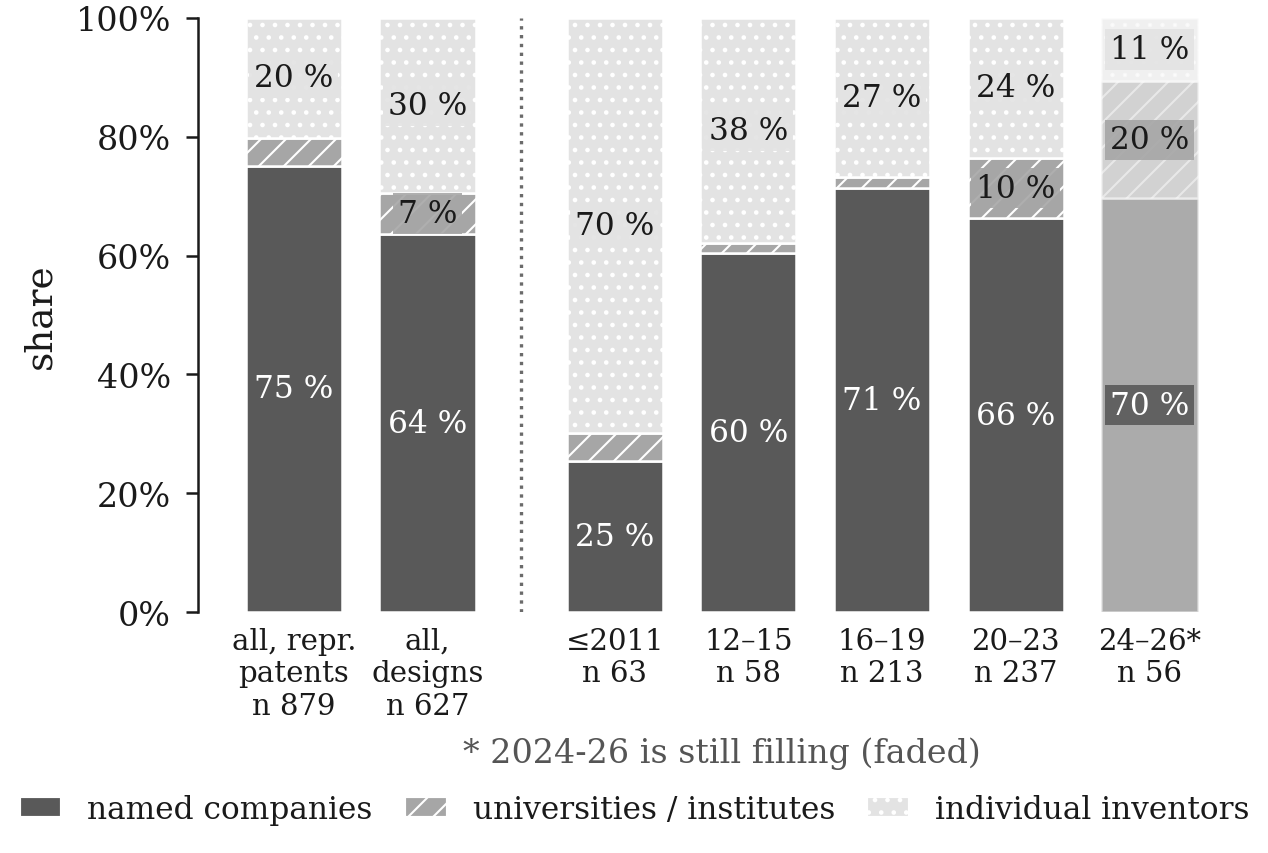

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V1_who_files/main/q2_filer_types.pdf


In [2]:
show('q2_filer_types')

### Cumulative share held by the largest assignees

`q2_largest_filers_share` · main · figure · from Figure 16 (i)

labels changed in q2_largest_filers_share: firm → assignee ×1; named organisations → named assignees ×2


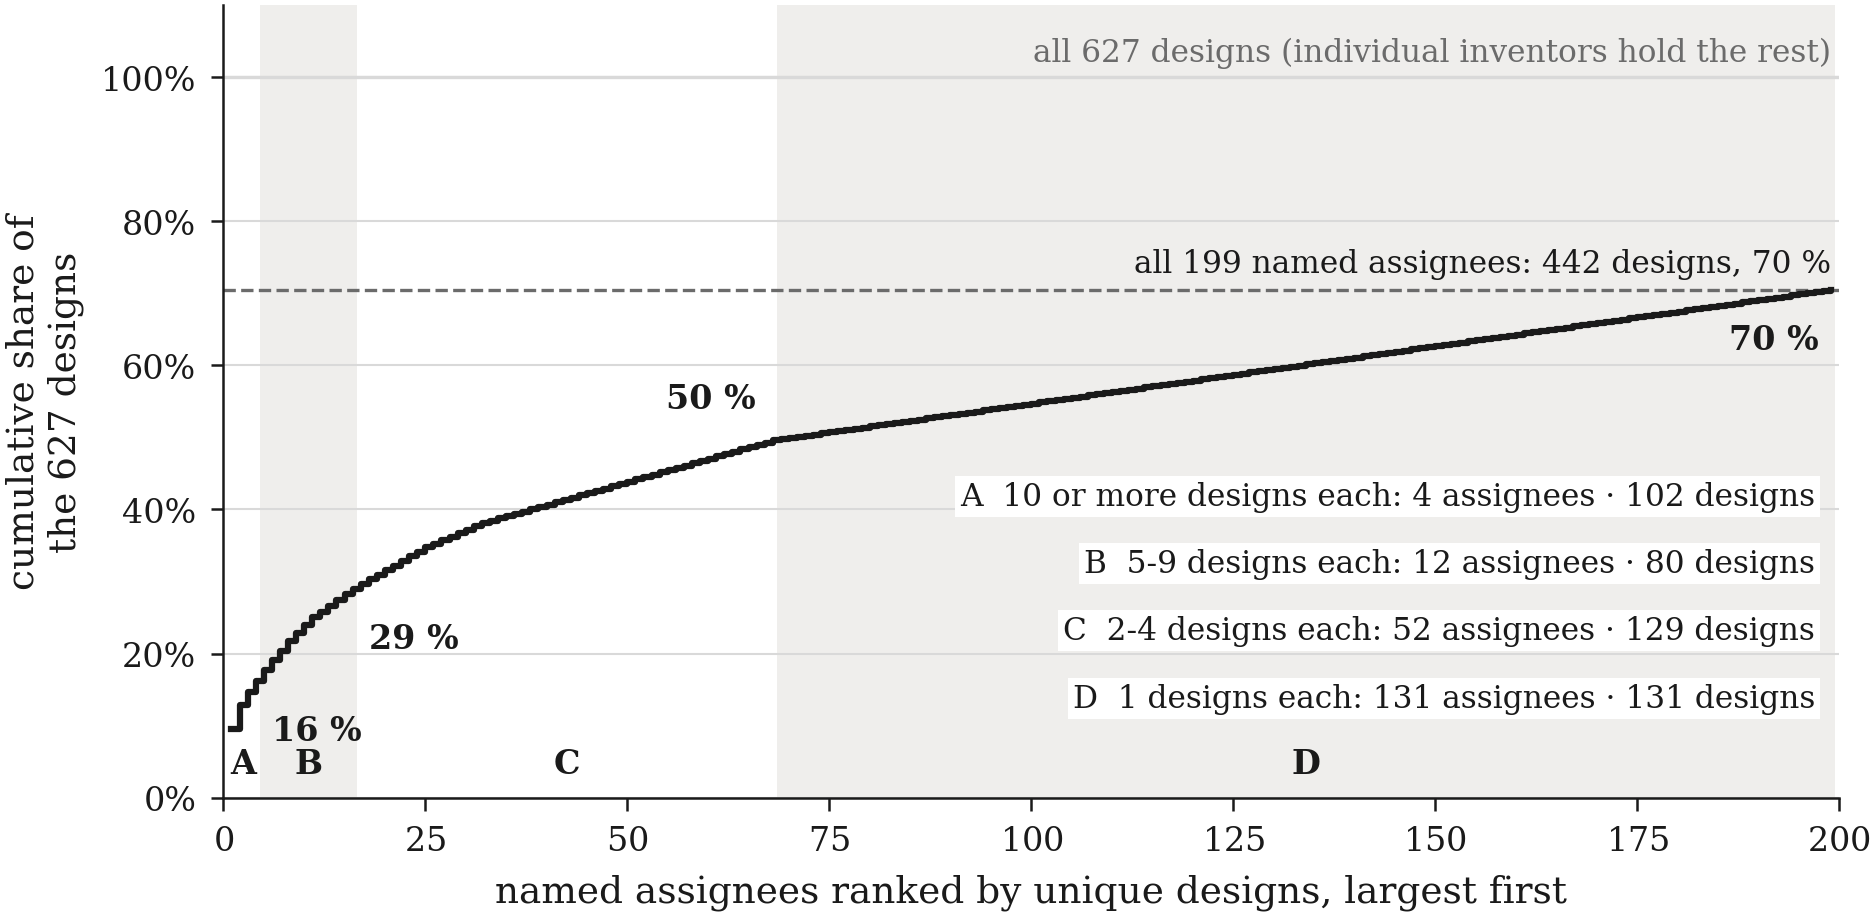

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V1_who_files/main/q2_largest_filers_share.pdf


In [3]:
show('q2_largest_filers_share')

### Largest assignee of each architecture

`q2_largest_filer_per_class` · main · table · from Figure 17 (i)

In [4]:
show('q2_largest_filer_per_class')

labels changed in q2_largest_filer_per_class: Multirotor → Multicopter ×1; Tilt Body → Tilt Frame ×1; class → architecture ×1; filer → assignee ×1; filers → assignees ×2; window → cohort ×1


,architecture,aircraft,assignees,effective assignees,"largest assignee, all years",its share,highest share in one cohort
0,Lift + Cruise,165,105,57,Airbus,7 %,"29 % (one inventor, before 2012)"
1,Tilt Propulsor,151,100,25,Bell / Textron,18 %,"34 % (Bell / Textron, in 2016-19)"
2,Combined Vectored Thrust,106,66,24,Bell / Textron,16 %,"21 % (Bell / Textron, in 2016-19)"
3,Tilt Wing,56,43,25,Bell / Textron,14 %,"21 % (Bell / Textron, in 2020-23)"
4,Multicopter,48,36,26,Airbus,8 %,"25 % (Airbus, in 2016-19)"
5,Pitch-to-Cruise,25,21,18,Airbus,12 %,"25 % (Airbus, in 2016-19)"
6,Tilt Frame,24,20,13,Bell / Textron,21 %,"33 % (Bell / Textron, in 2016-19)"


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V1_who_files/main/q2_largest_filer_per_class.csv


## V.2 New and returning assignees

*Does the pool of assignees renew itself, and do the new ones file different architectures?*

### First-time and returning assignees per cohort

`q2_first_vs_returning_filers` · appendix · figure · from Figure 16 (iii)

labels changed in q2_first_vs_returning_filers: firms → assignees ×3; named organisations → named assignees ×1; window → cohort ×1


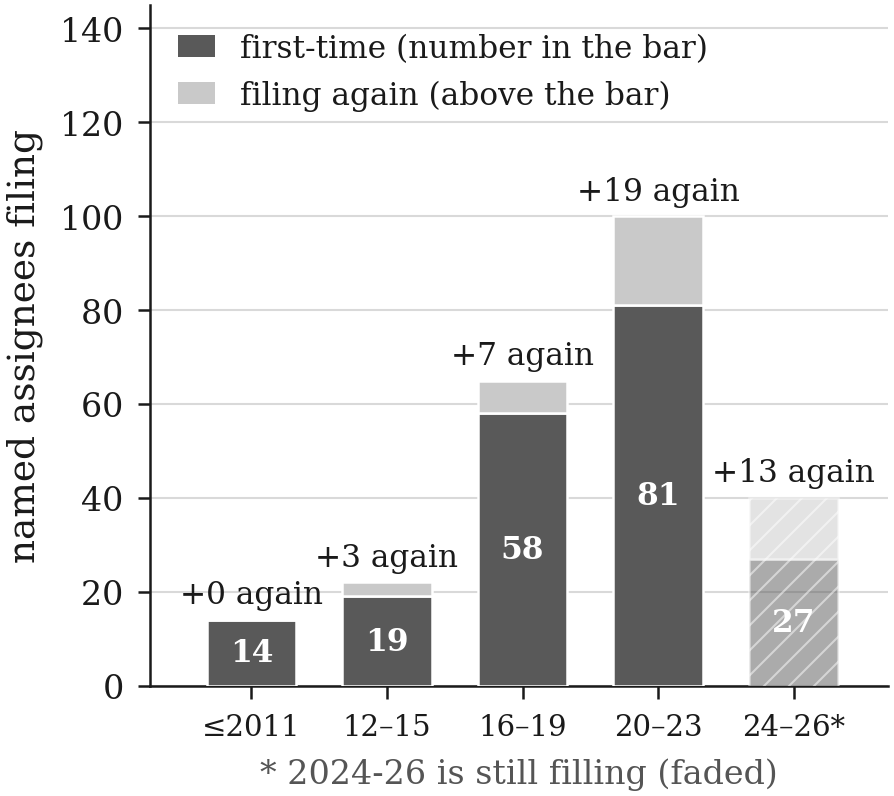

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V2_new_and_returning_assignees/appendix/q2_first_vs_returning_filers.pdf


In [5]:
show('q2_first_vs_returning_filers')

### Architectures of first-time and returning assignees

`q2_entrant_class_mix` · appendix · figure · from Figure 19 (i)

labels changed in q2_entrant_class_mix: Multirotor → Multicopter ×1; Tilt Rotor → Tilt Propulsor ×1; classes → architectures ×1; filers → assignees ×8; firm → assignee ×1; firms → assignees ×2; window → cohort ×1


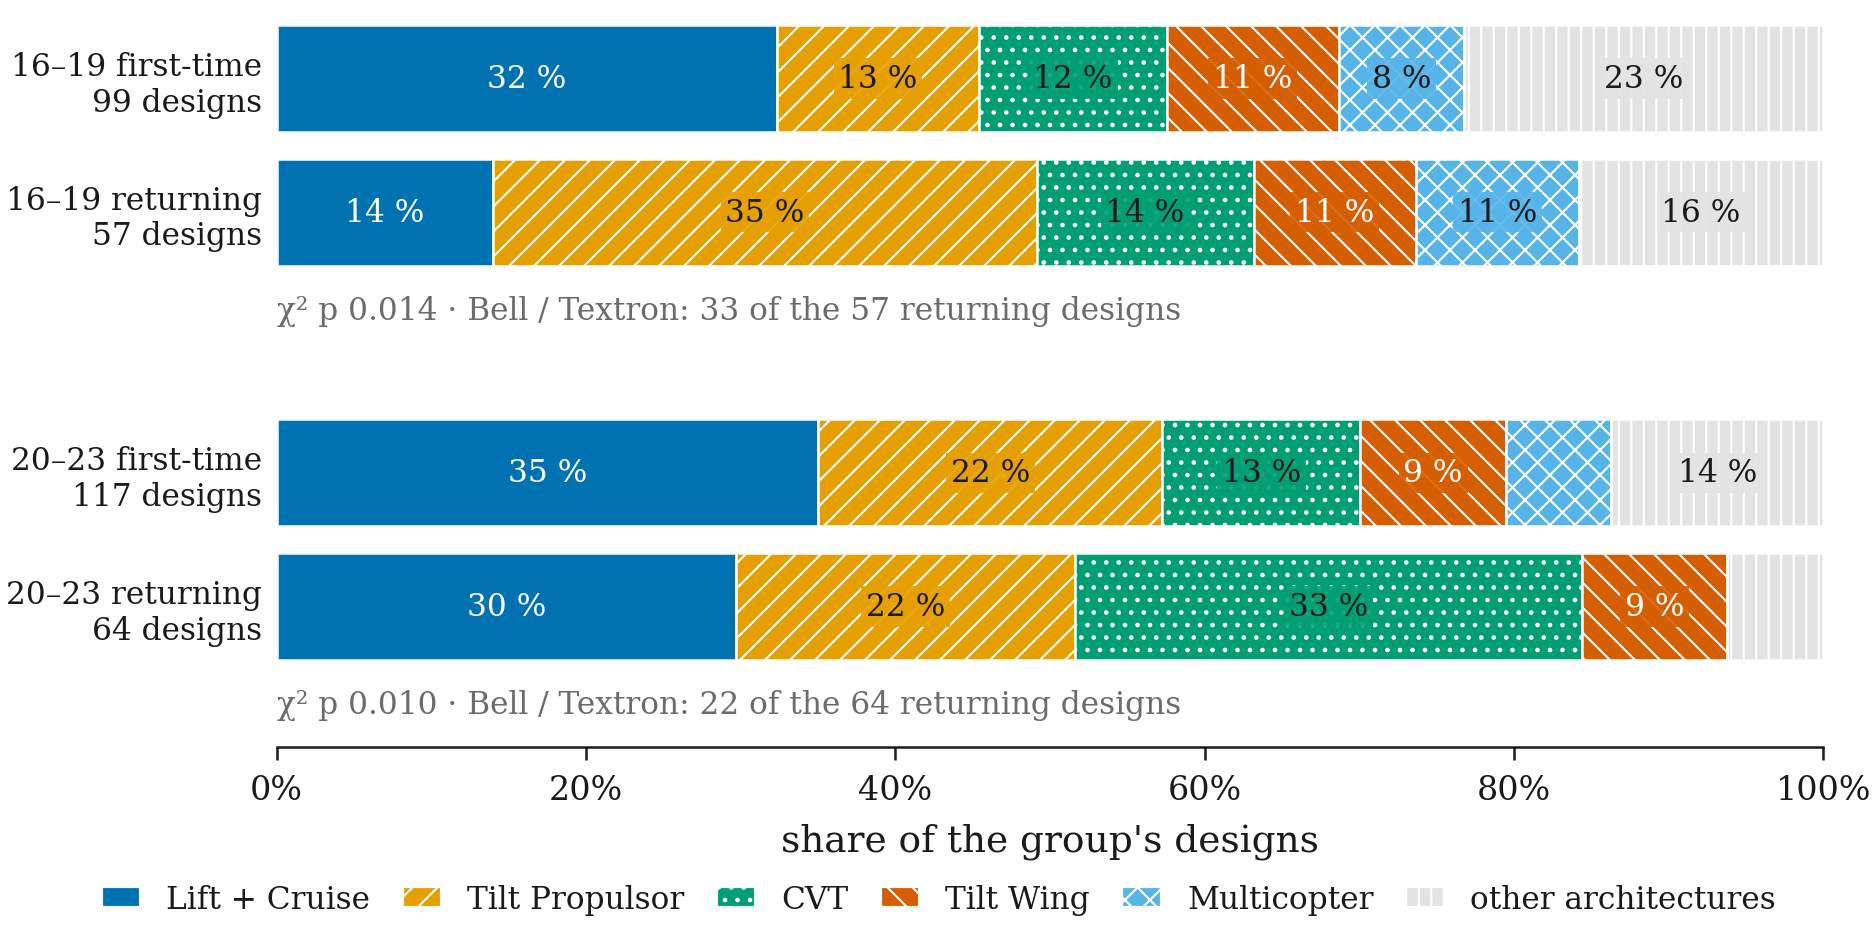

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V2_new_and_returning_assignees/appendix/q2_entrant_class_mix.pdf


In [6]:
show('q2_entrant_class_mix')

### Tilt Wing among the entering assignees

`q2_tilt_wing_entrants` · appendix · figure · from Figure 19 (ii)

labels changed in q2_tilt_wing_entrants: firms → assignees ×1; window → cohort ×3


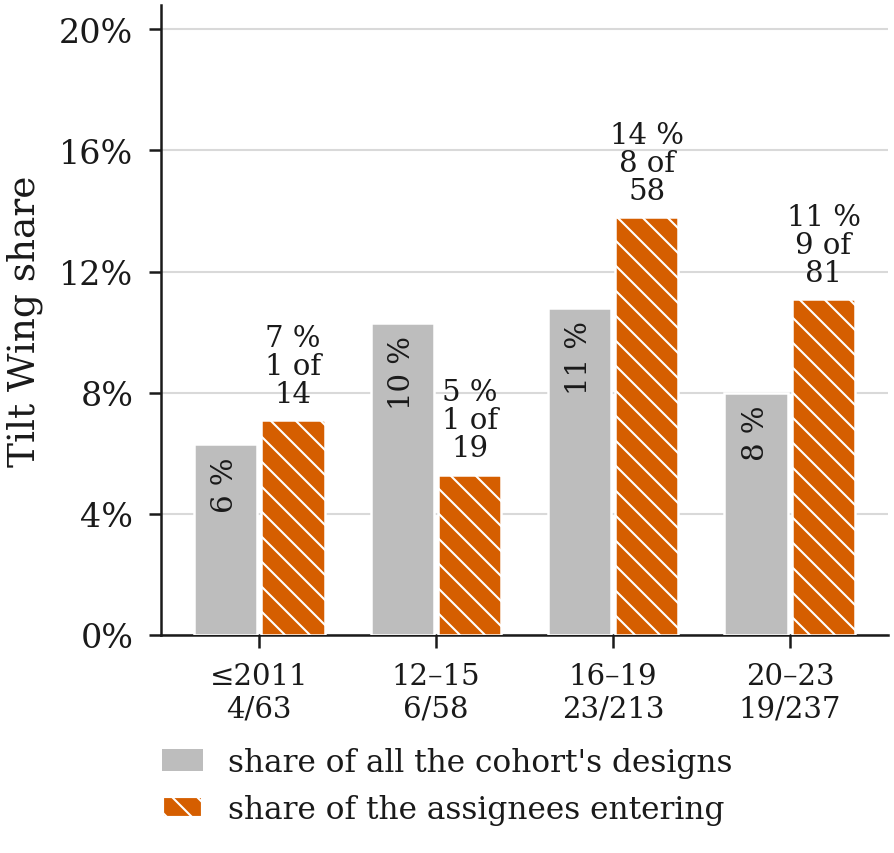

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V2_new_and_returning_assignees/appendix/q2_tilt_wing_entrants.pdf


In [7]:
show('q2_tilt_wing_entrants')

## V.3 What each region files, and when it enters

*Do the regions file different designs, and do they enter each architecture at different times?*

### What each region files, all years

`q3_region_design_all_years` · main · figure · from Figure 22 (all years bars)

labels changed in q3_region_design_all_years: class → architecture ×3


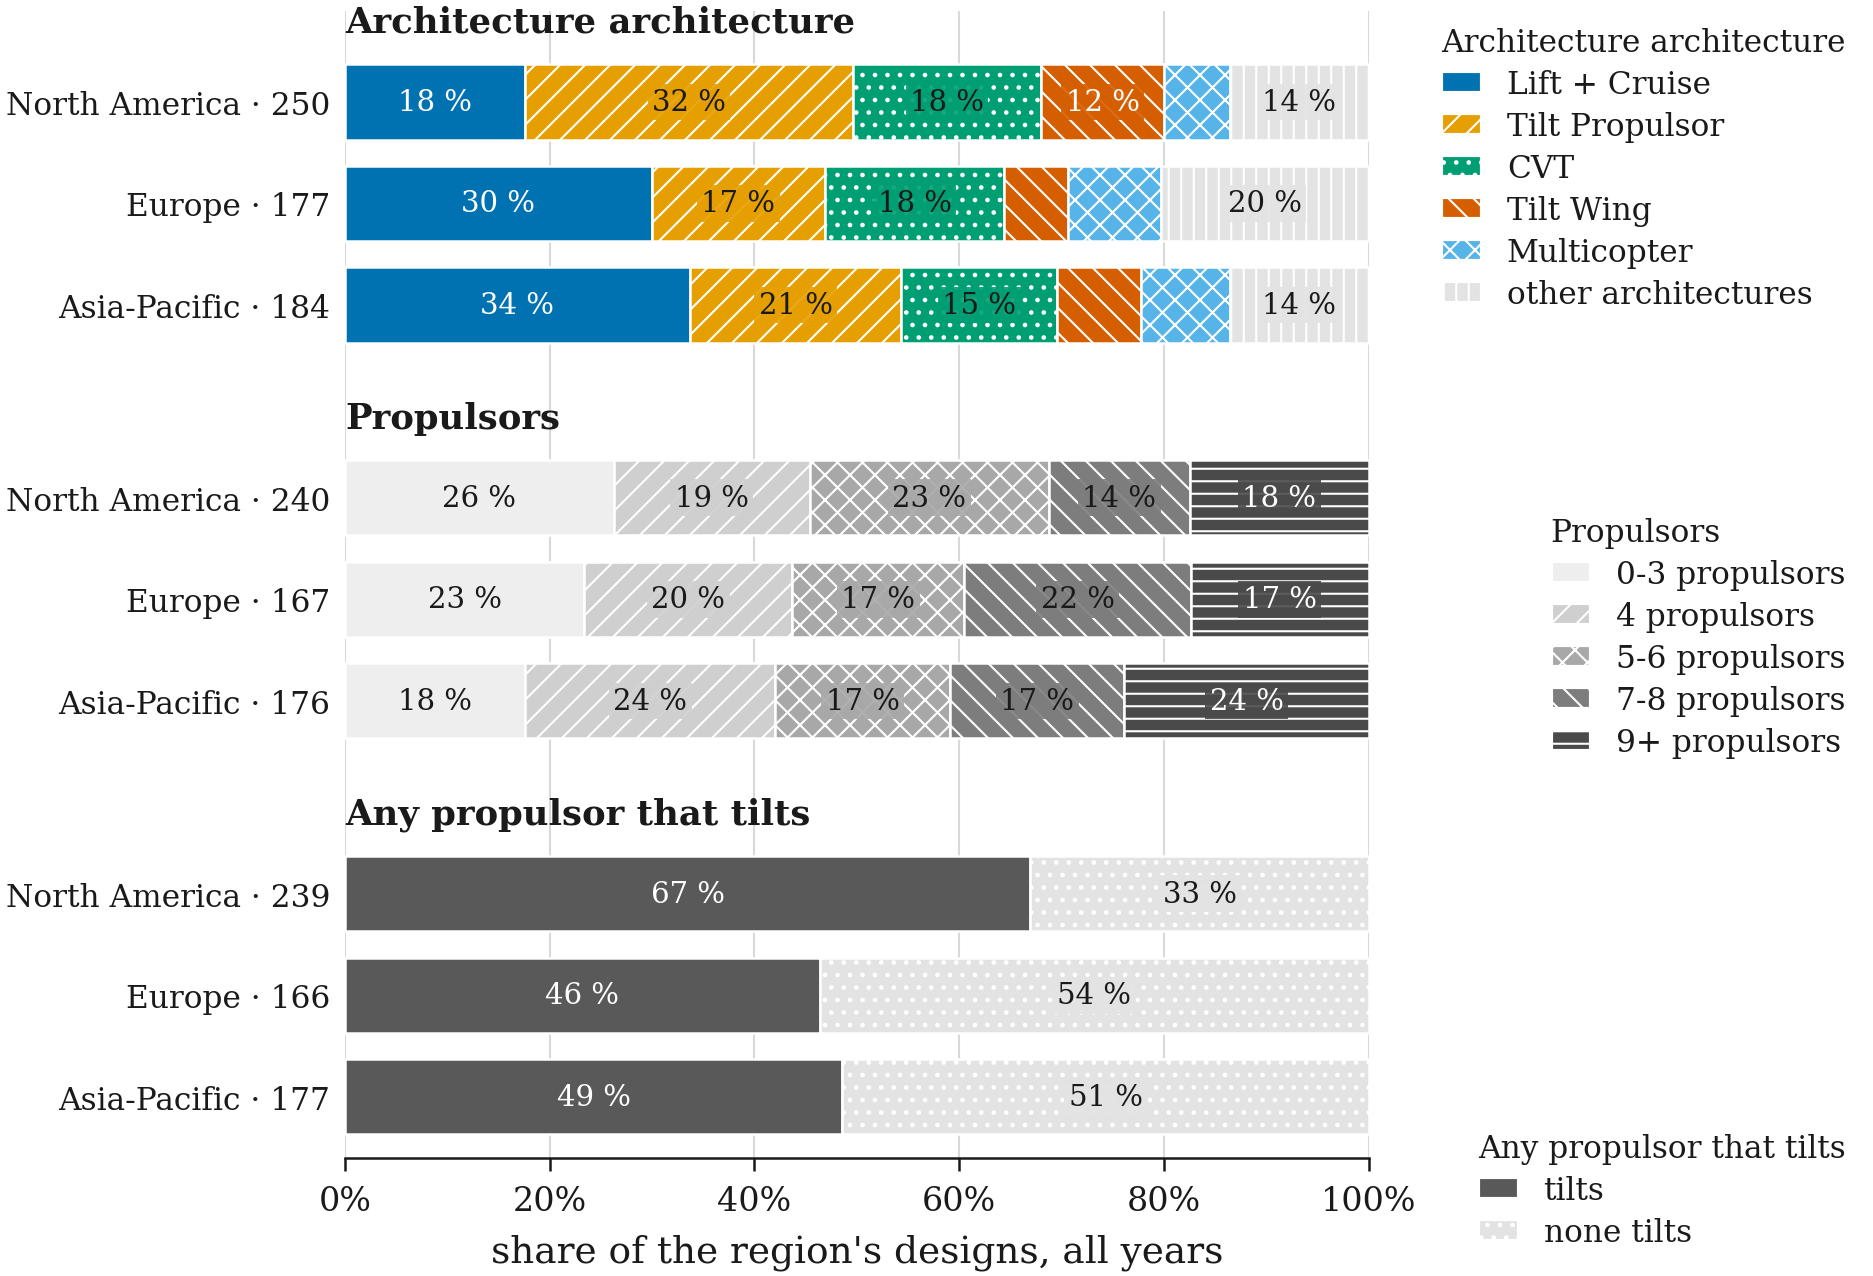

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/main/q3_region_design_all_years.pdf


In [8]:
show('q3_region_design_all_years')

### Years after North America, per architecture

`q3_region_entry_lag` · main · figure · from Figure 23 (ii)

labels changed in q3_region_entry_lag: Multirotor → Multicopter ×3; Tilt Rotor → Tilt Propulsor ×3; class → architecture ×1


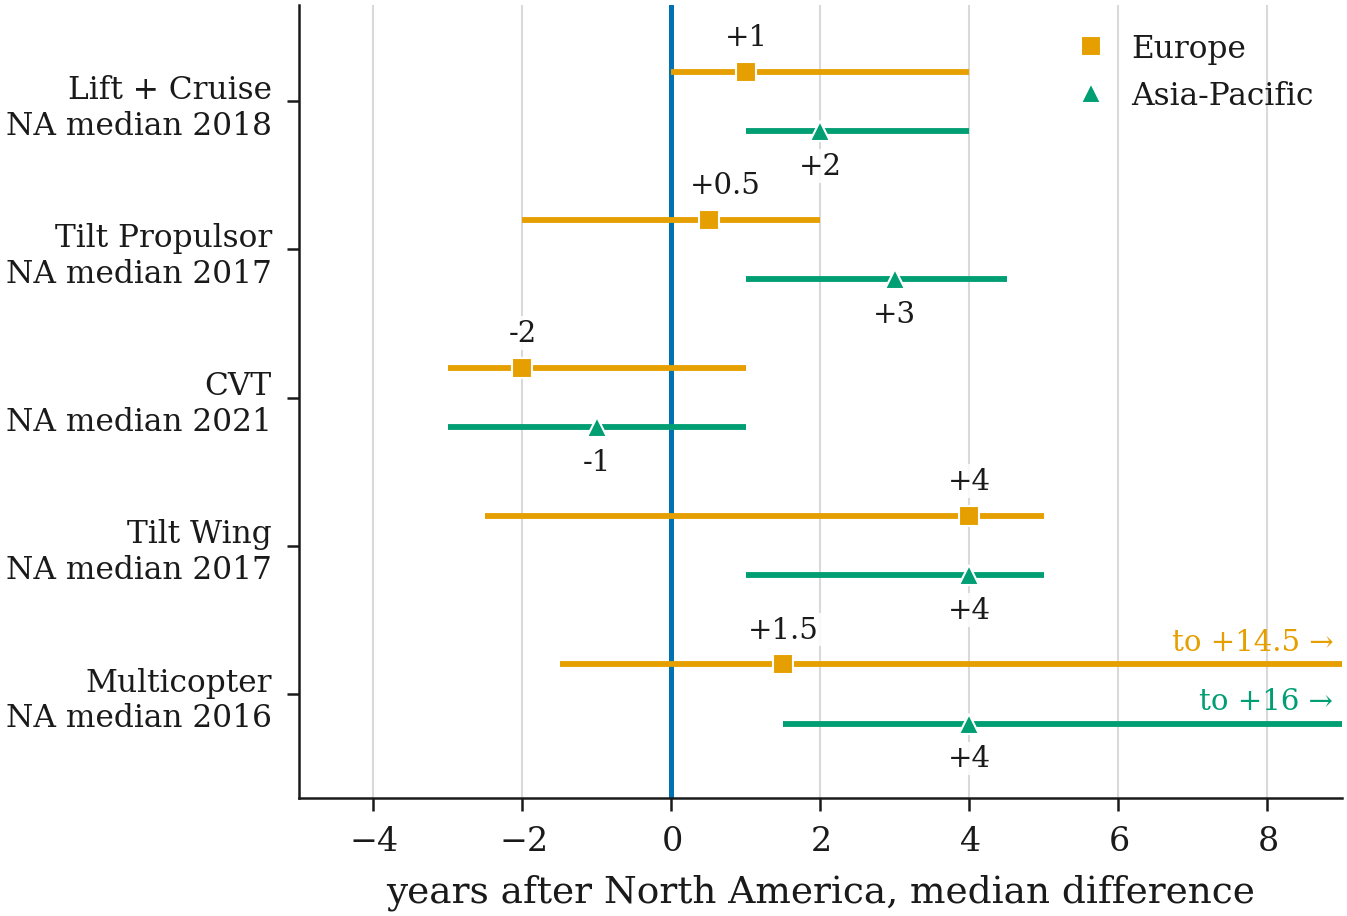

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/main/q3_region_entry_lag.pdf


In [9]:
show('q3_region_entry_lag')

### Architecture per region and cohort

`q3_region_mix_by_window_class` · appendix · figure · from Figure 22 (i), per-cohort bars

labels changed in q3_region_mix_by_window_class: class → architecture ×15; window → cohort ×1


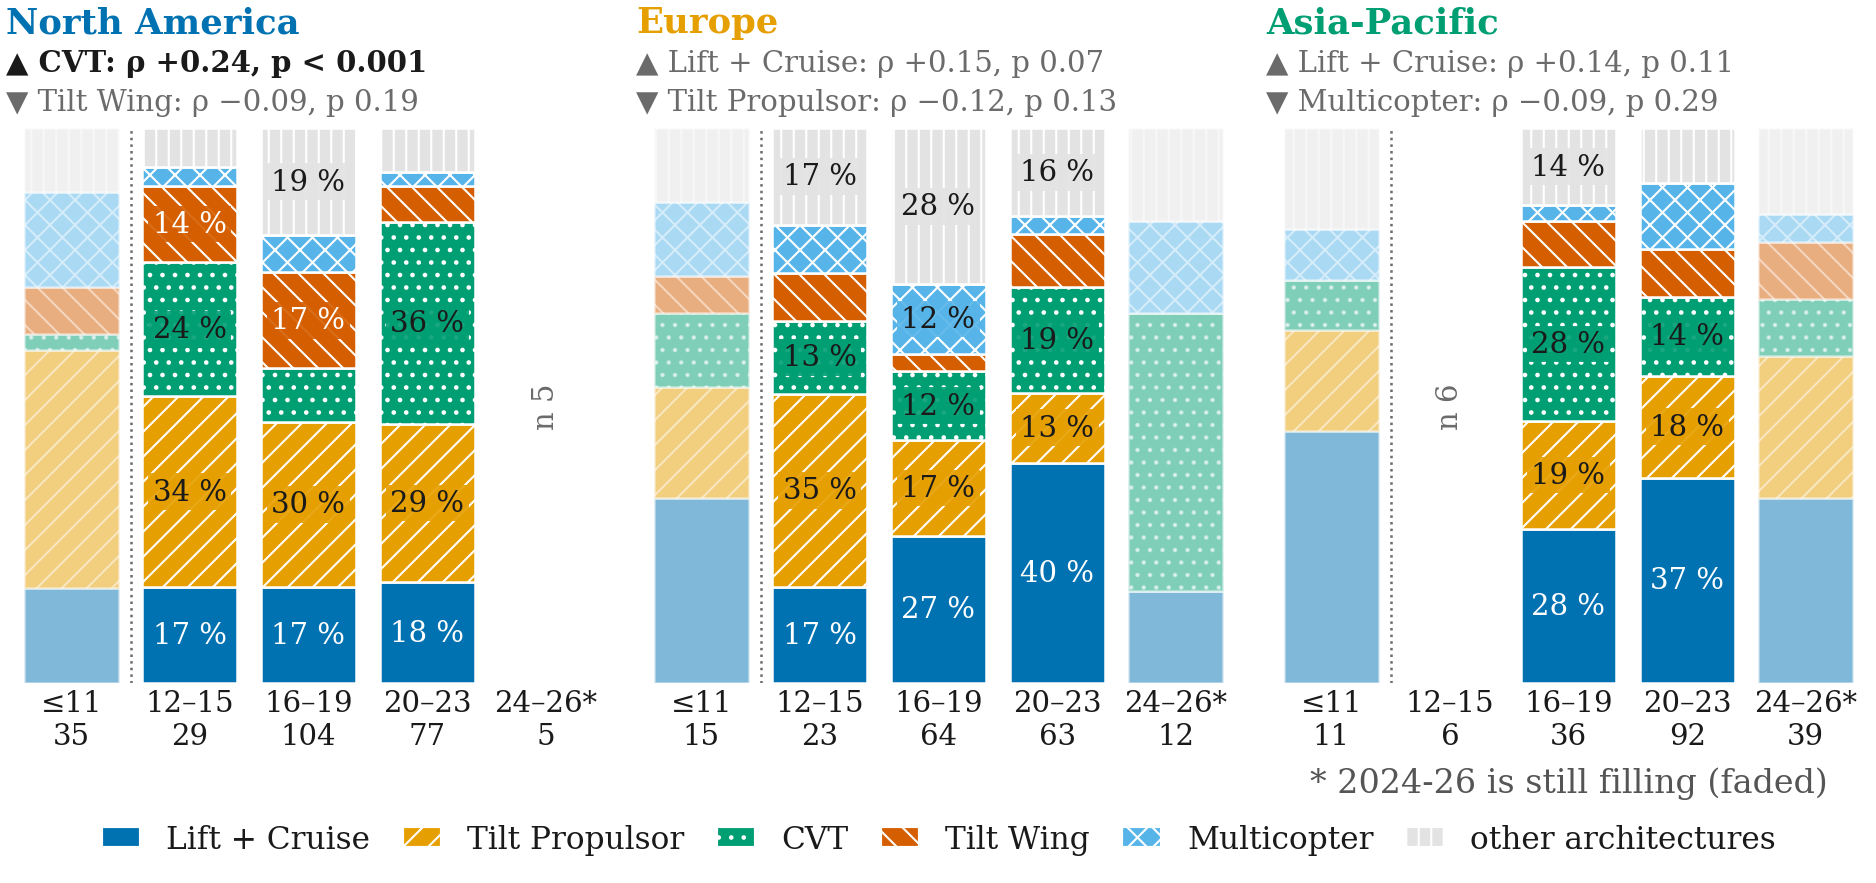

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_mix_by_window_class.pdf


In [10]:
show('q3_region_mix_by_window_class')

### Propulsor units per region and cohort

`q3_region_mix_by_window_units` · appendix · figure · from Figure 22 (ii), per-cohort bars

labels changed in q3_region_mix_by_window_units: window → cohort ×1


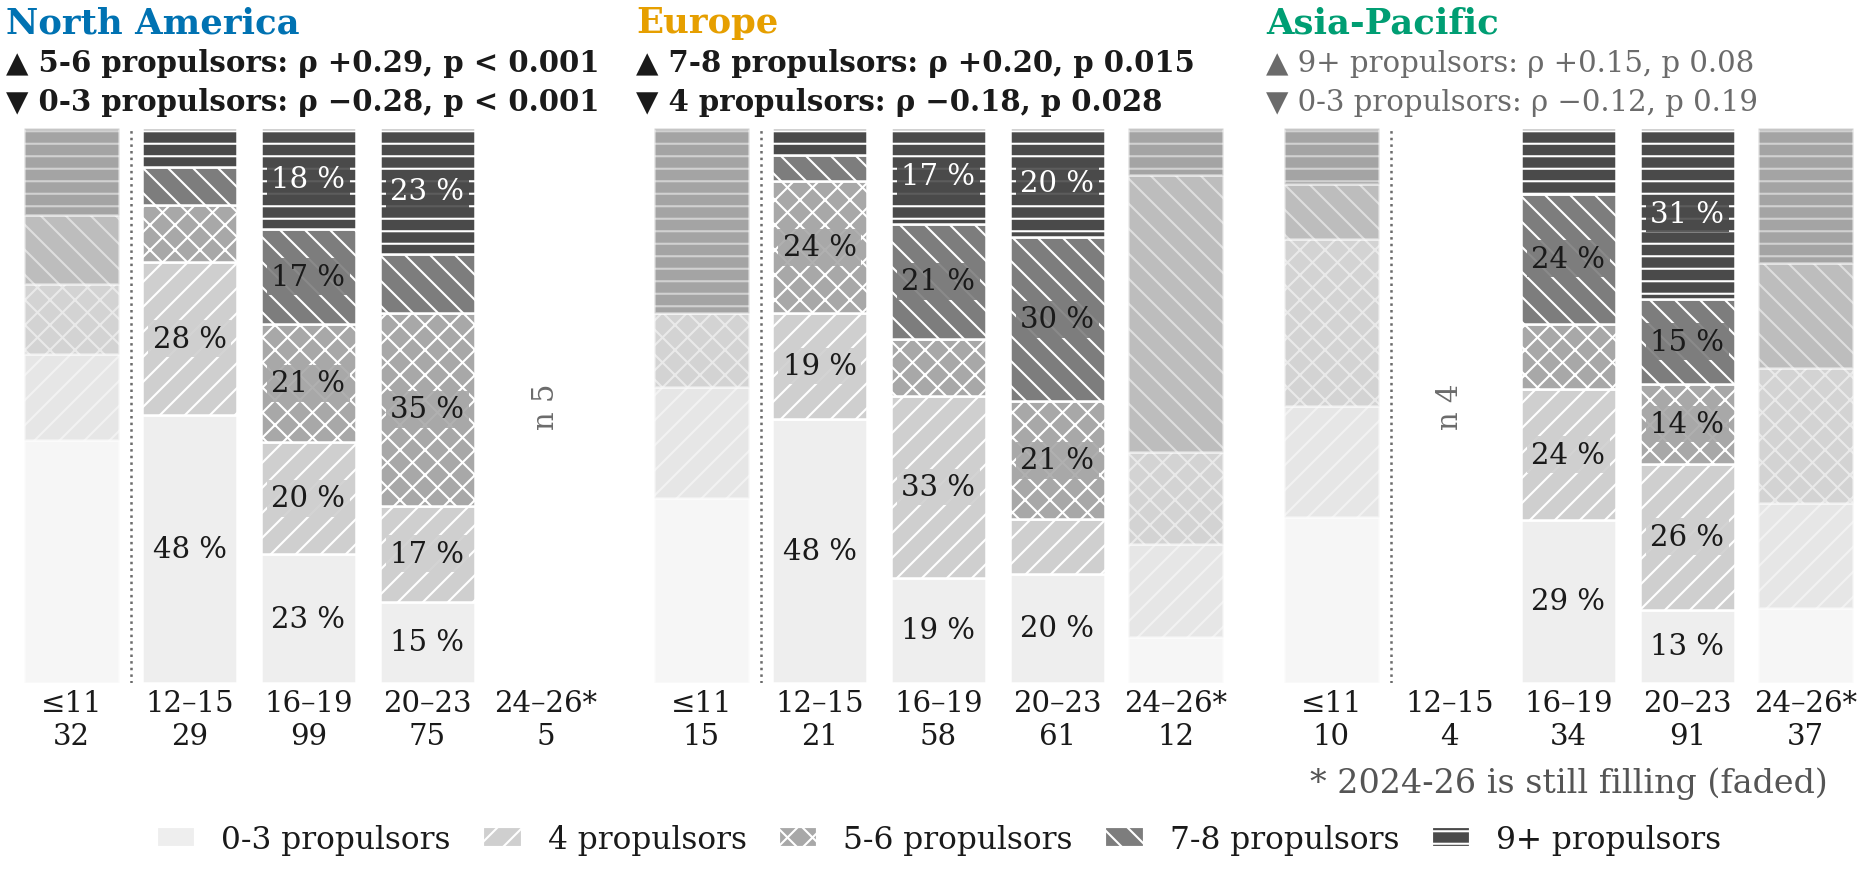

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_mix_by_window_units.pdf


In [11]:
show('q3_region_mix_by_window_units')

### Tilting share per region and cohort

`q3_region_mix_by_window_tilting` · appendix · figure · from Figure 22 (iii), per-cohort bars

labels changed in q3_region_mix_by_window_tilting: window → cohort ×1


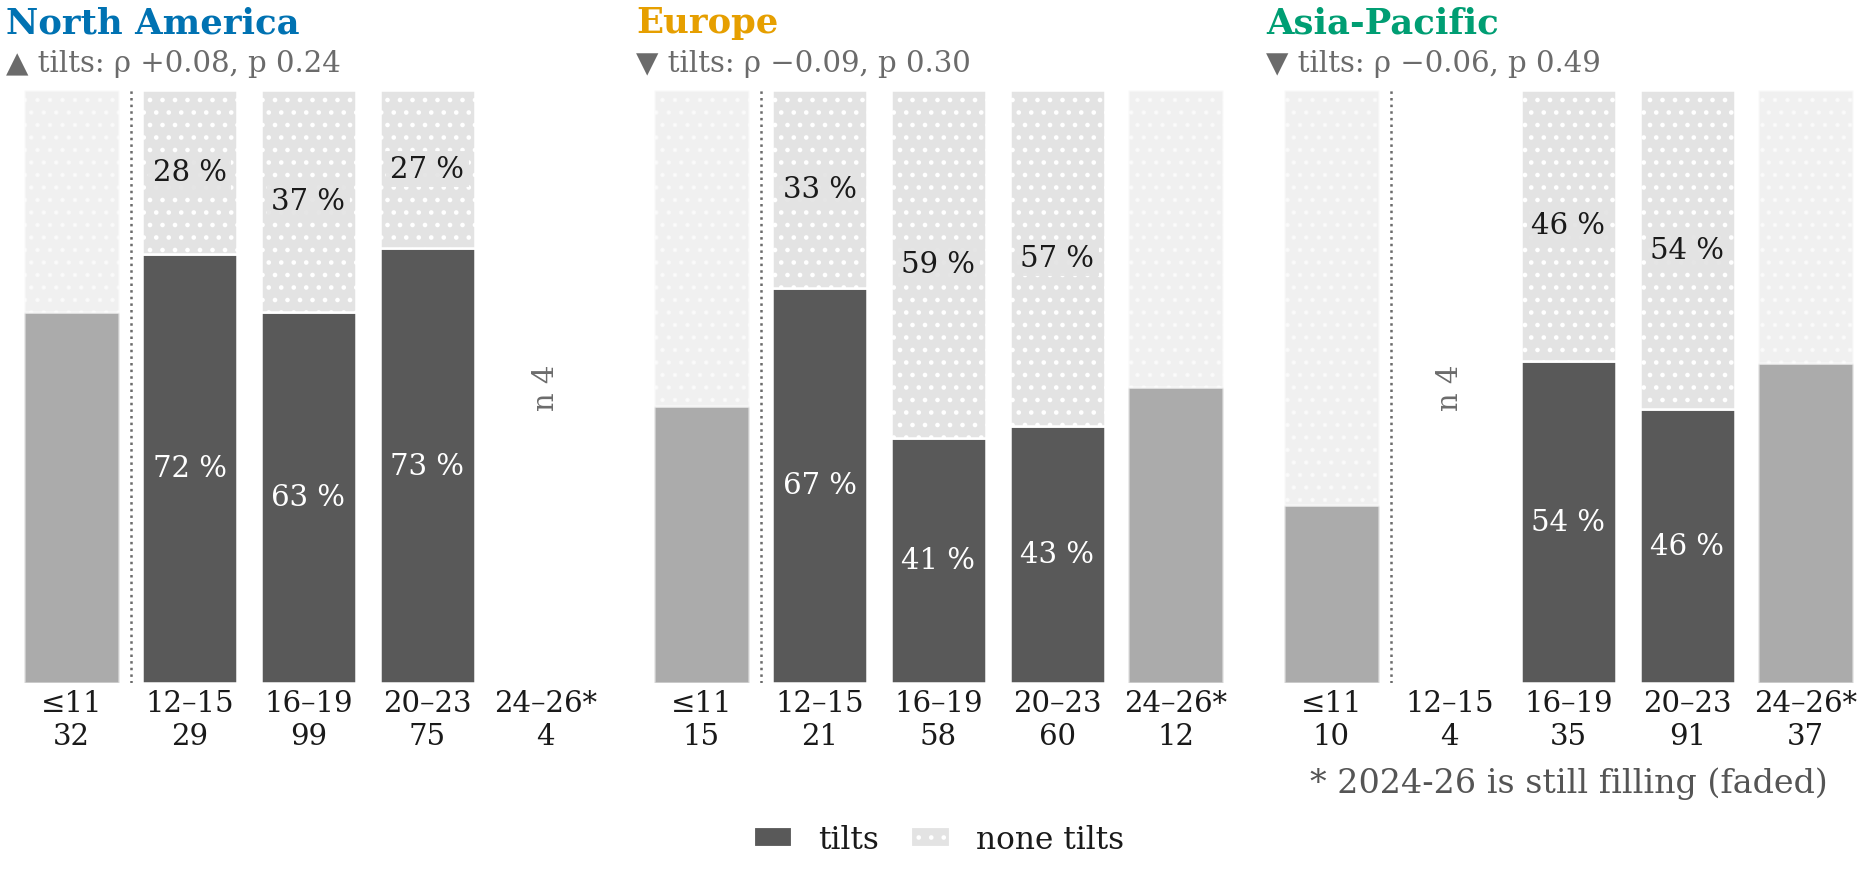

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_mix_by_window_tilting.pdf


In [12]:
show('q3_region_mix_by_window_tilting')

### The applicant countries behind the regions

`q3_region_countries` · appendix · figure · from Figure 21

labels changed in q3_region_countries: none


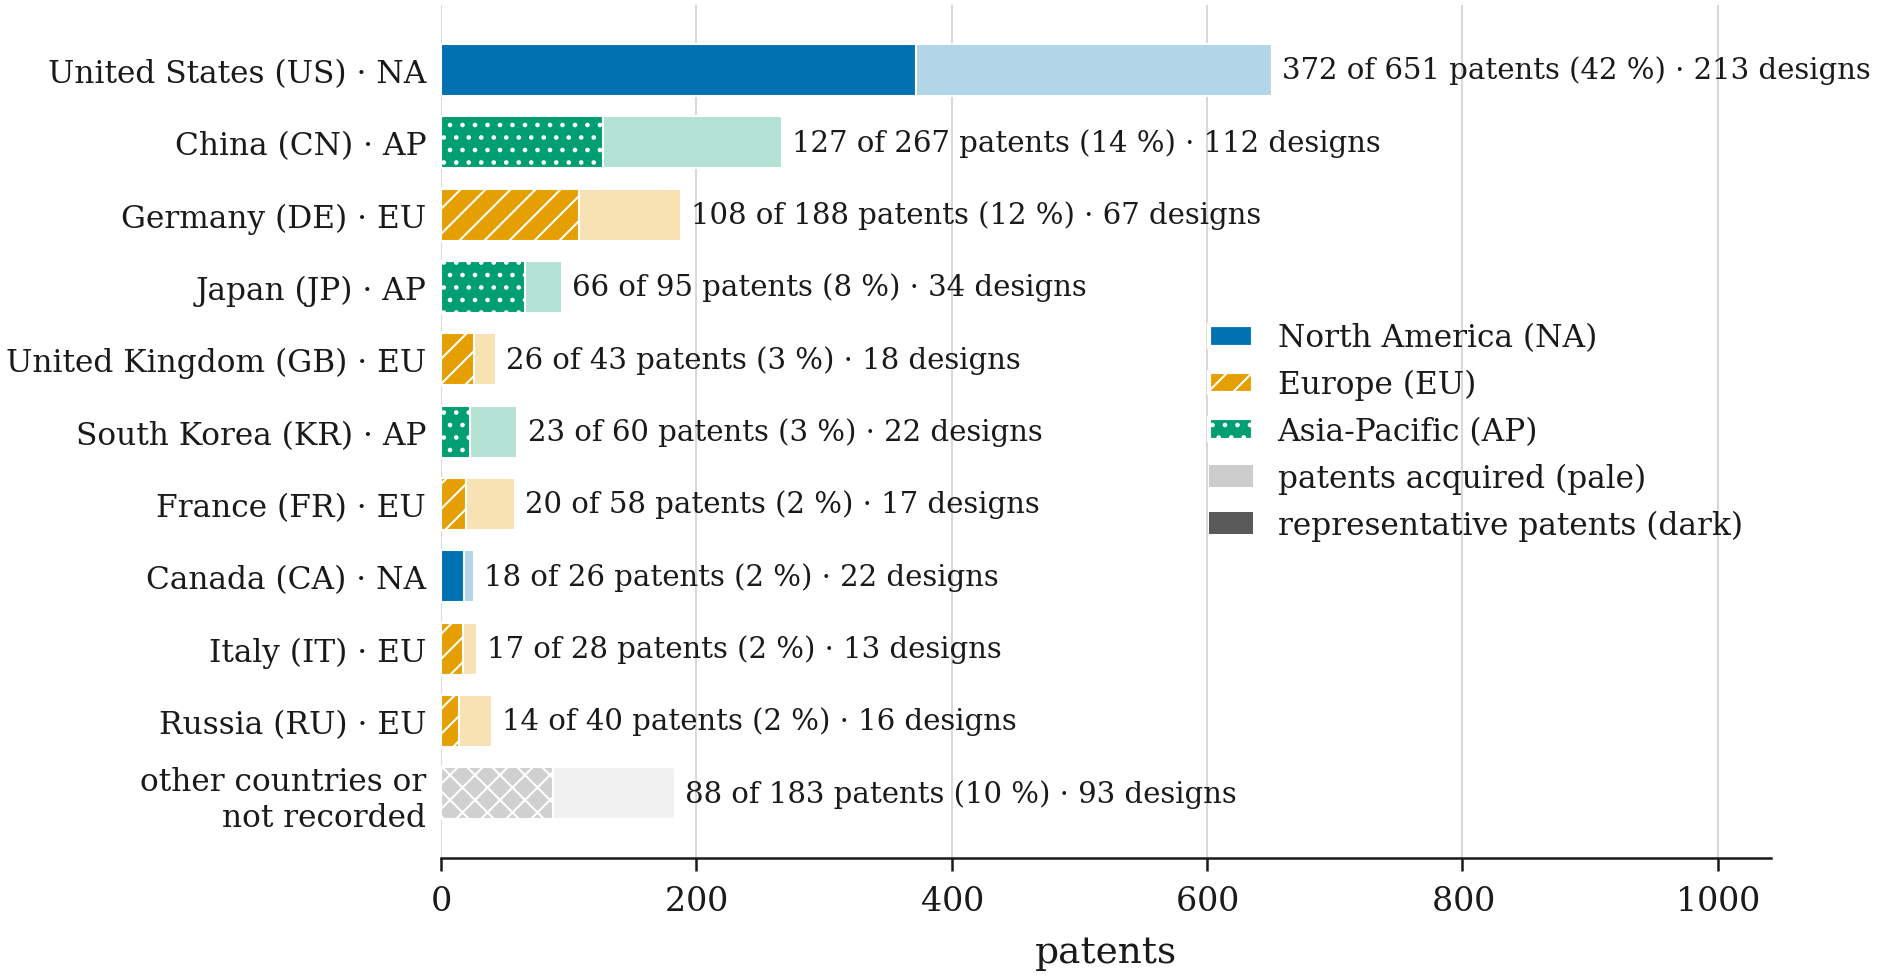

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V3_regions_what_and_when/appendix/q3_region_countries.pdf


In [13]:
show('q3_region_countries')

## V.4 The regions and the tilting family F

*Does the share of F, or the tilting lean, differ between the regions?*

### Family F share per region and cohort

`q7_region_family_share` · main · figure · from Figure 24 (i)

labels changed in q7_region_family_share: none


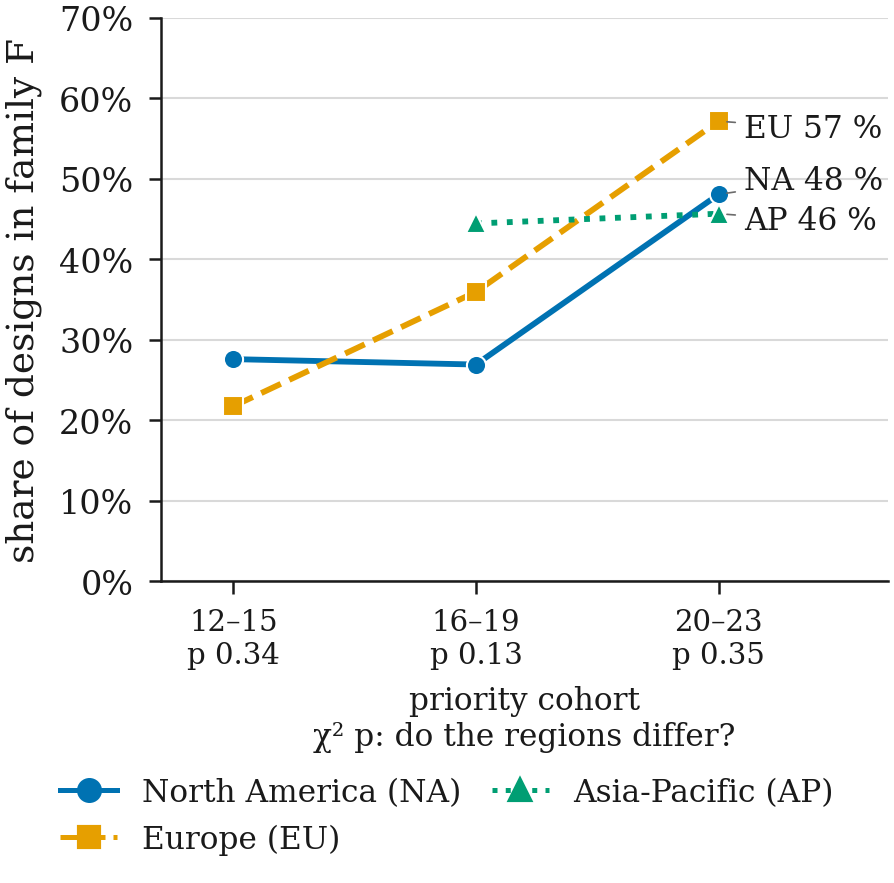

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V4_regions_and_family_F/main/q7_region_family_share.pdf


In [14]:
show('q7_region_family_share')

### Tilting lean with and without the largest assignee

`q7_region_lean_without_largest_filer` · appendix · figure · from Figure 24 (ii)

labels changed in q7_region_lean_without_largest_filer: Tilt Rotor → Tilt Propulsor ×4; filer → assignee ×1


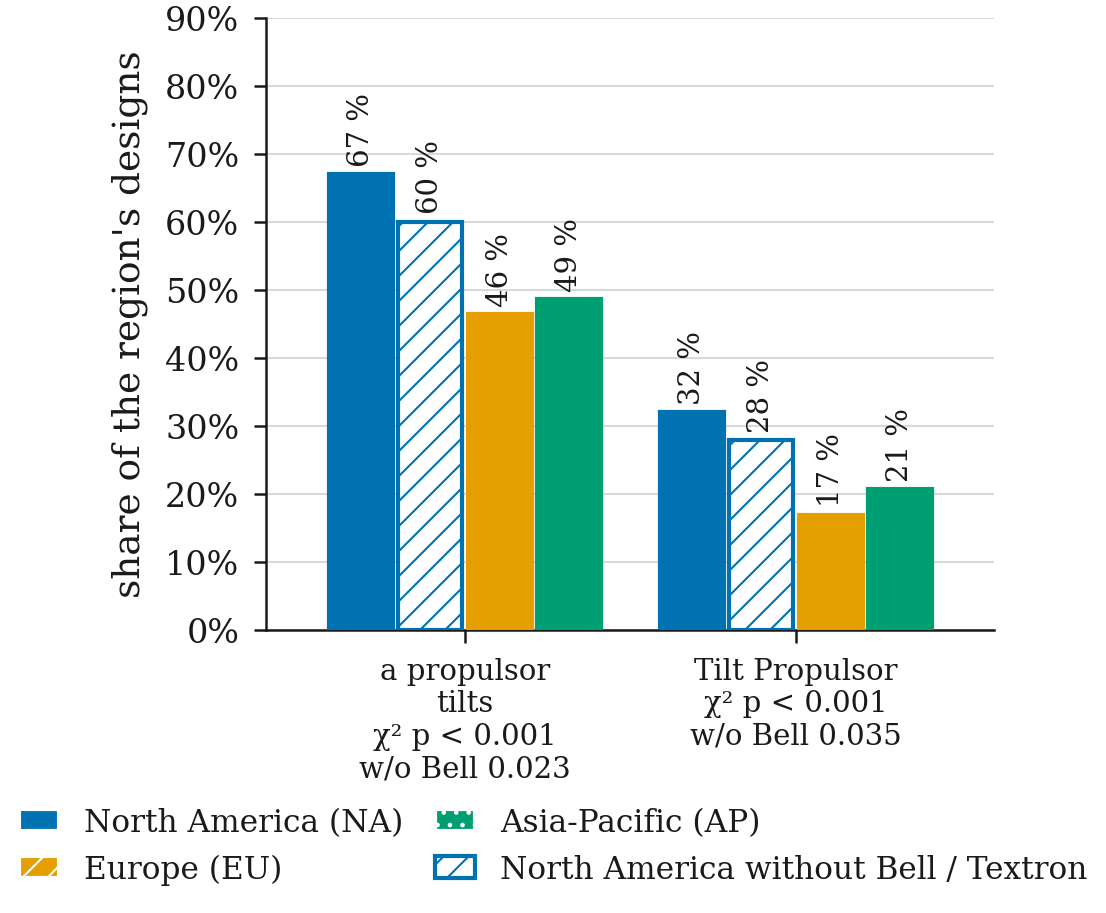

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/V4_regions_and_family_F/appendix/q7_region_lean_without_largest_filer.pdf


In [15]:
show('q7_region_lean_without_largest_filer')

## Numbers for the text

In [16]:
from viz import analysis5 as a5
n = a5.numbers_for_text(ctx)
a5.print_numbers(n)

1. Share of designs per region (all aircraft of the cohort in the denominator)
           cohort  designs North America Europe Asia-Pacific others sum of the three
        all years      627        39.9 % 28.2 %       29.7 %  2.2 %           97.8 %
          2012-15       58        50.0 % 39.7 %       10.3 %  0.0 %          100.0 %
          2016-19      213        48.8 % 30.0 %       17.8 %  3.3 %           96.7 %
          2020-23      237        32.5 % 26.6 %       38.8 %  2.1 %           97.9 %
2024-26 (partial)       56         8.9 % 21.4 %       69.6 %  0.0 %          100.0 %

2. Entry lag, median priority-year offset from North America, 95 % bootstrap interval
   priority years             architecture       region  aircraft  offset vs North America (years)                    interval touches or includes 0
all years to 2023 Combined vectored thrust       Europe        25                             -2.0                -3.0 to +1.0                   YES
all years to 2023 Combined

## Layout check, all figures

Every row should read 0 and 0. A row that does not names the texts that collide.

In [17]:
chk = pd.DataFrame(CHECKS)
display(chk)
figs = chk[chk['problems'] != 'table']
print('all figures pass' if (figs['text over text'] == 0).all() and (figs['under 6.5 pt'] == 0).all() else 'SOME FIGURES NEED A FIX (see the table)')

,file,group,role,text over text,under 6.5 pt,problems
0,q2_filer_types,V1_who_files,main,0,0,
1,q2_largest_filers_share,V1_who_files,main,0,0,
2,q2_largest_filer_per_class,V1_who_files,main,,,table
3,q2_first_vs_returning_filers,V2_new_and_returning_assignees,appendix,0,0,
4,q2_entrant_class_mix,V2_new_and_returning_assignees,appendix,0,0,
5,q2_tilt_wing_entrants,V2_new_and_returning_assignees,appendix,0,0,
6,q3_region_design_all_years,V3_regions_what_and_when,main,0,0,
7,q3_region_entry_lag,V3_regions_what_and_when,main,0,0,
8,q3_region_mix_by_window_class,V3_regions_what_and_when,appendix,0,0,
9,q3_region_mix_by_window_units,V3_regions_what_and_when,appendix,0,0,


all figures pass


## README and file list

Rewrite the folder's README.md and list every file written.

In [18]:
import subprocess
print(subprocess.run([sys.executable, str(PILLAR / 'notebooks' / '_build' / 'write_readme_53.py')], capture_output=True, text=True).stdout)
files = sorted(p.relative_to(OUT) for p in OUT.rglob('*') if p.is_file())
print(len(files), 'files'); files

README written /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_V_assignees_and_regions/README.md

55 files


[PosixPath('README.md'),
 PosixPath('V1_who_files/main/q2_filer_types.csv'),
 PosixPath('V1_who_files/main/q2_filer_types.json'),
 PosixPath('V1_who_files/main/q2_filer_types.pdf'),
 PosixPath('V1_who_files/main/q2_filer_types.png'),
 PosixPath('V1_who_files/main/q2_largest_filer_per_class.csv'),
 PosixPath('V1_who_files/main/q2_largest_filer_per_class.json'),
 PosixPath('V1_who_files/main/q2_largest_filers_share.csv'),
 PosixPath('V1_who_files/main/q2_largest_filers_share.json'),
 PosixPath('V1_who_files/main/q2_largest_filers_share.pdf'),
 PosixPath('V1_who_files/main/q2_largest_filers_share.png'),
 PosixPath('V2_new_and_returning_assignees/appendix/q2_entrant_class_mix.csv'),
 PosixPath('V2_new_and_returning_assignees/appendix/q2_entrant_class_mix.json'),
 PosixPath('V2_new_and_returning_assignees/appendix/q2_entrant_class_mix.pdf'),
 PosixPath('V2_new_and_returning_assignees/appendix/q2_entrant_class_mix.png'),
 PosixPath('V2_new_and_returning_assignees/appendix/q2_first_vs_returni

## Hand-over to the dissertation (LaTeX_v15)

The seven figures of Analysis V remade at their final width (text block 16 cm, height at most 55 % of the width, text 7 pt or more) by `viz/latex_v15_partv.py`, with the data behind each, `NUMBERS_V.md` and the manifest lines. Nothing is recomputed differently; the builders are those above.

In [19]:
from viz import latex_v15_partv as hand
infos = hand.export_part_v(cfg, ctx)
for i in infos:
    print(i['name'], i['width_cm'], 'x', i['height_cm'], 'cm | h/w', i['height_over_width'], '| smallest', i['smallest_pt'], 'pt | overlaps', len(i['overlaps']))

labels changed in q2_filer_types: none


labels changed in q3_region_design_all_years: class → architecture ×3


labels changed in q7_region_family_share: none


labels changed in q2_largest_filers_share: firm → assignee ×1; named organisations → named assignees ×4


labels changed in q3_region_entry_lag: Multirotor → Multicopter ×3; Tilt Rotor → Tilt Propulsor ×3; class → architecture ×1


labels changed in q7_region_firm_proximity: none


labels changed in q3_firm_successions: Multi-
rotor → Multi-
copter ×1


q2_filer_types 10.56 x 5.81 cm | h/w 0.55 | smallest 7.0 pt | overlaps 0
q3_region_design_all_years 16.0 x 8.8 cm | h/w 0.55 | smallest 7.0 pt | overlaps 0
q7_region_family_share 11.2 x 6.16 cm | h/w 0.55 | smallest 7.0 pt | overlaps 0
q2_largest_filers_share 16.0 x 7.87 cm | h/w 0.492 | smallest 7.5 pt | overlaps 0
q3_region_entry_lag 11.52 x 6.34 cm | h/w 0.55 | smallest 7.0 pt | overlaps 0
q7_region_firm_proximity 11.2 x 6.16 cm | h/w 0.55 | smallest 7.0 pt | overlaps 0
q3_firm_successions 16.0 x 8.63 cm | h/w 0.54 | smallest 7.5 pt | overlaps 0
